## 1. Setup

In [20]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR    = "./data/titanic"

TRAIN_PATH  = os.path.join(DATA_DIR, "train.csv")  #  TRAIN_PATH = f"{DATA_DIR}/train.csv" is also available
TEST_PATH   = os.path.join(DATA_DIR, "test.csv")
SAMPLE_PATH = os.path.join(DATA_DIR, "gender_submission.csv")

TARGET = "Survived"
ID     ="PassengerId"

#### 1.1. Data load

In [3]:
# Never change original data 0 series
train_0  = pd.read_csv(TRAIN_PATH)
test_0   = pd.read_csv(TEST_PATH)
sample_0 = pd.read_csv(SAMPLE_PATH)

train  = train_0.copy()
test   = test_0.copy()
sample = sample_0.copy()

#### 1.2. Categorize

In [14]:
# insert numerical column to list and drop ID, TARGET
num_cols = train.select_dtypes(include="number").columns.drop([ID, TARGET]).tolist()

# insert category column to list
cat_cols = train.select_dtypes(exclude="number").columns.drop(["Name"]).tolist()

print("Numerical columns: ", num_cols)
print("Category columns:  ", cat_cols, "   /   Drop 'Name'")

print("-" * 30)
# test
print("\nAge vs Survived with missing data")
train.groupby(train["Age"].isna())[TARGET].agg(["mean", "size"]).round(3)

Numerical columns:  ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Age_missing']
Category columns:   ['Sex', 'Ticket', 'Cabin', 'Embarked']    /   Drop 'Name'
------------------------------

Age vs Survived with missing data


,mean,size
Age,,
False,0.406,714
True,0.294,177


`Claude instruction`  
> True の行が「Age が欠損している人」です。ここで生存率に差があれば、FE のときに Age_missing のような「欠損しているかどうか」を表す列を作る意味があります。
> 生存率は、Age が欠損している人で 0.294、欠損していない人で 0.406 ですね。この差は、Age_missing という「欠損していたら 1、していなければ 0」の列にすればモデルに渡せます。
```python
# Create BEFORE imputing Age (after fillna, isna() is all False)
for df in (train, test):
    df["Age_missing"] = df["Age"].isna().astype(int)

train.groupby("Age_missing")[TARGET].agg(["mean", "size"])   # check
```

1. Age を埋める前に作ってください。 fillna の後では isna() がすべて False になり、情報が消えてしまいます。後で Name から Title（Mr / Mrs / Miss / Master）を作り、Title 別の中央値で Age を補完するときも、順番は「Age_missing を作る → Age を補完する」です。
2. test にも同じ処理をします。 上のコードは for df in (train, test) で両方に列を足しています。train にしか列がないと、予測のときにエラーになります。
3. Pclass の影響が混ざっていないか確認してください。 Age の欠損は3等客室の乗客に偏っているかもしれません。その場合、生存率が低いのは「欠損しているから」ではなく「3等だから」の可能性があります。


## 2. Exploratory Data Analysis

#### 2.1. Distribution of numerical columns

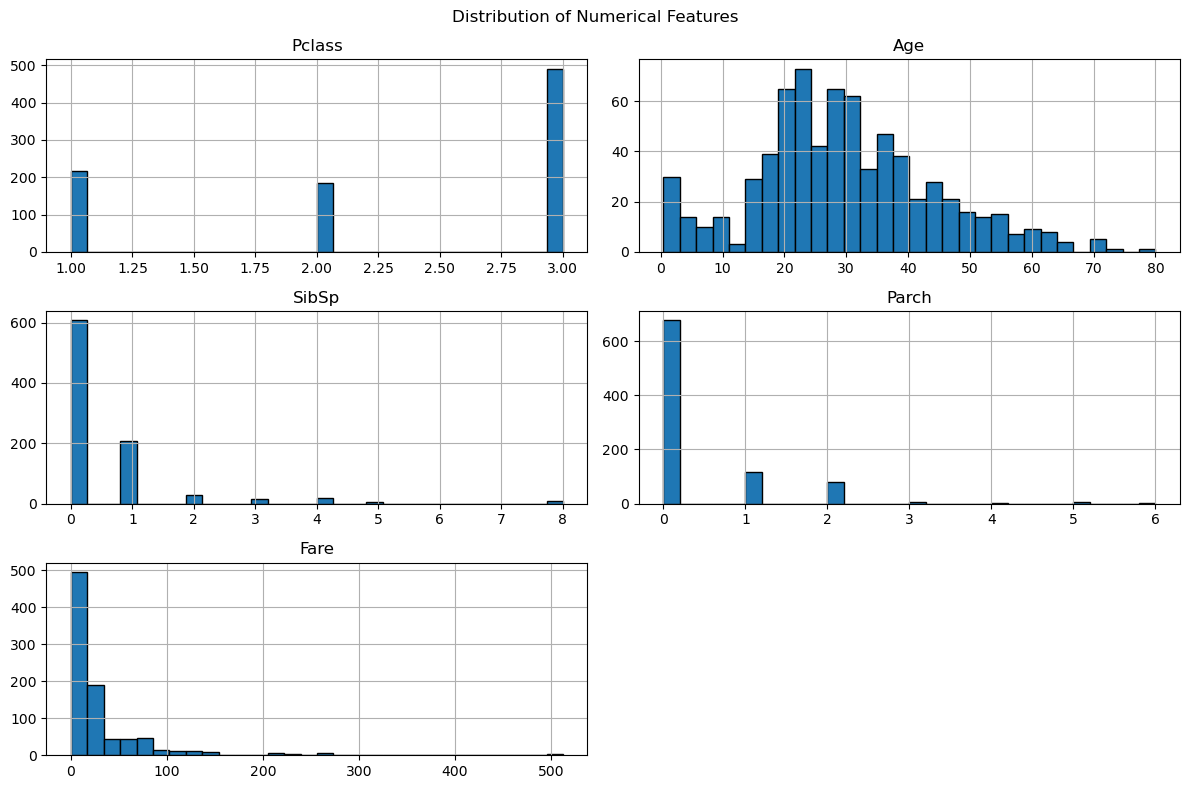

In [5]:
train[num_cols].hist(
    bins = 30,
    figsize=(12, 8),
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

#### 2.2. Numerical column VS Survived

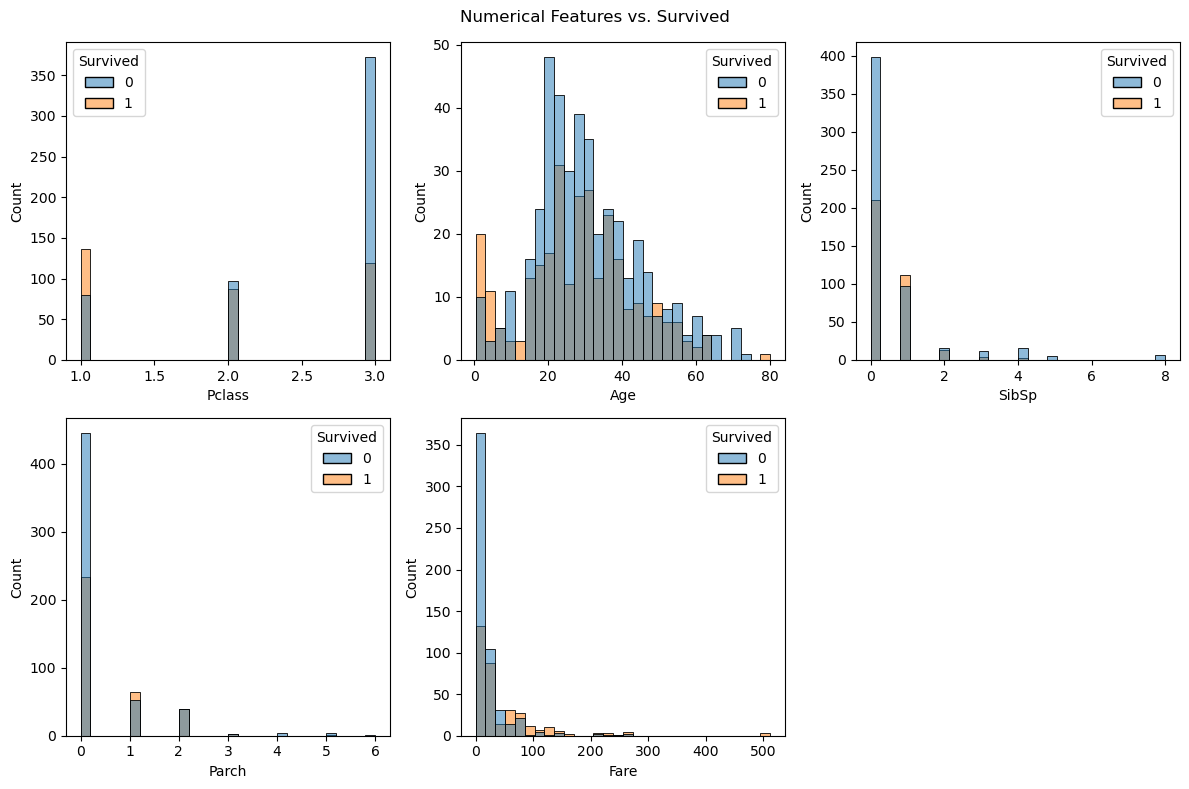

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=train, x=col, hue=TARGET, bins=30, edgecolor='black', ax=ax)

axes.flat[-1].set_visible(False)   # 5 columns -> hide the empty 6th panel

plt.suptitle('Numerical Features vs. Survived')
plt.tight_layout()
plt.show()

#### 2.3. Numerical column VS Survived (Claude code version)

**Preparation**

In [7]:
# Survived colors: keep the same in every plot (1 = blue, 0 = orange)
PALETTE = {1: "#2a78d6", 0: "#eb6834"}
GRAY    = "#898781"

disc_cols = [c for c in num_cols if train[c].nunique() <= 10]   # ['Pclass', 'SibSp', 'Parch']
cont_cols = [c for c in num_cols if c not in disc_cols]          # ['Age', 'Fare']
overall   = train[TARGET].mean()

def plot_survival_rate(ax, key, title):
    """Bar = survival rate per group, label = number of passengers (n)."""
    rate = train.groupby(key, observed=True)[TARGET].agg(["mean", "size"])
    bars = ax.bar(rate.index.astype(str), rate["mean"], color=PALETTE[1], width=0.7)
    ax.bar_label(bars, labels=[f"n={n}" for n in rate["size"]], fontsize=9)
    ax.axhline(overall, color=GRAY, linestyle="--", label=f"overall = {overall:.2f}")
    ax.set(ylim=(0, 1), ylabel="Survival rate", title=title)
    ax.legend()

**Discrete Features vs. Survived**

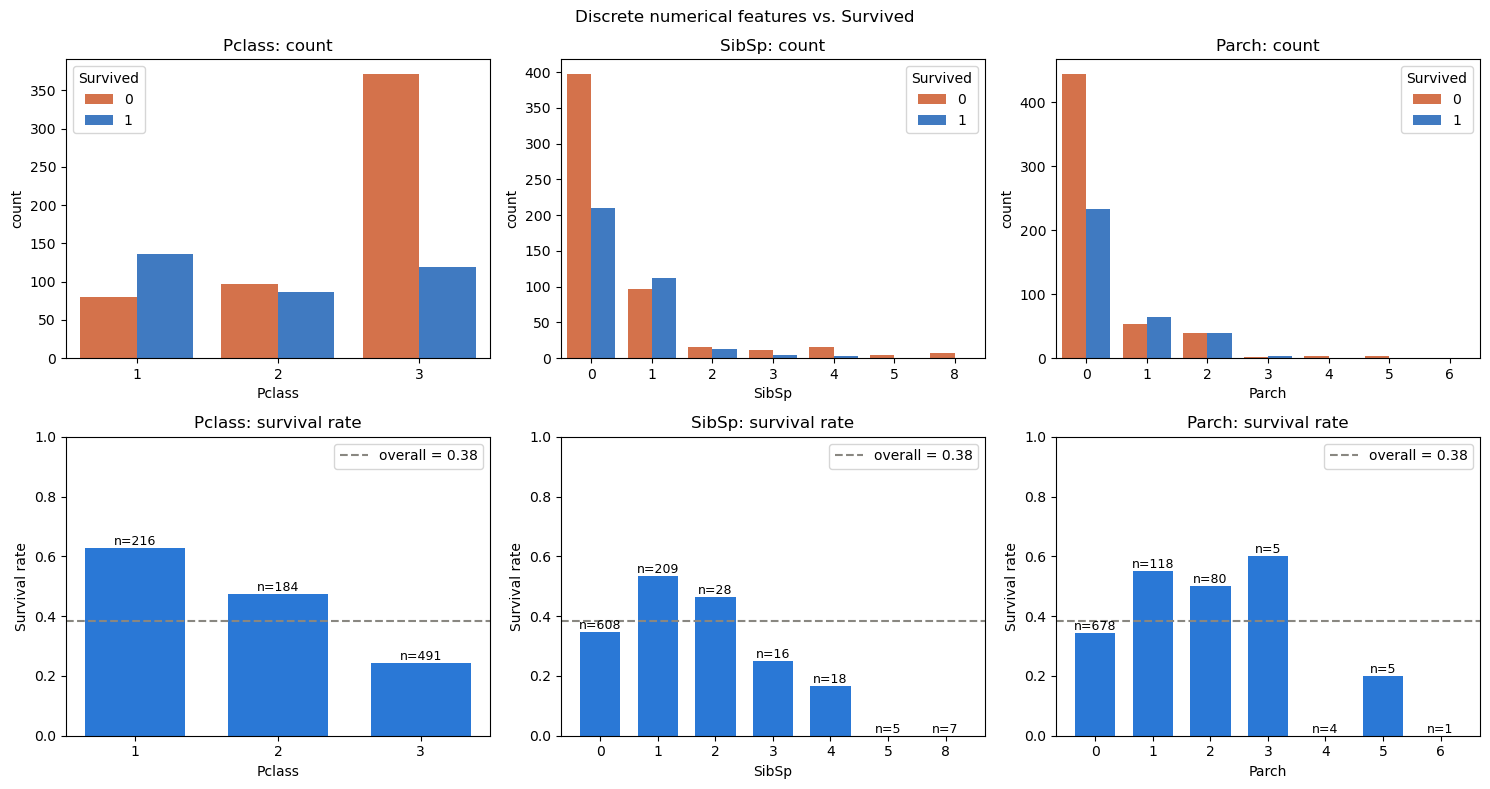

In [8]:
fig, axes = plt.subplots(2, len(disc_cols), figsize=(15, 8))

for i, col in enumerate(disc_cols):
    # Top: passenger count per value, split by Survived
    sns.countplot(data=train, x=col, hue=TARGET, palette=PALETTE, ax=axes[0, i])
    axes[0, i].set_title(f"{col}: count")

    # Bottom: survival rate per value
    plot_survival_rate(axes[1, i], col, f"{col}: survival rate")
    axes[1, i].set_xlabel(col)

plt.suptitle("Discrete numerical features vs. Survived")
plt.tight_layout()
plt.show()

**Distribution of Continuous Features by Survival Status**

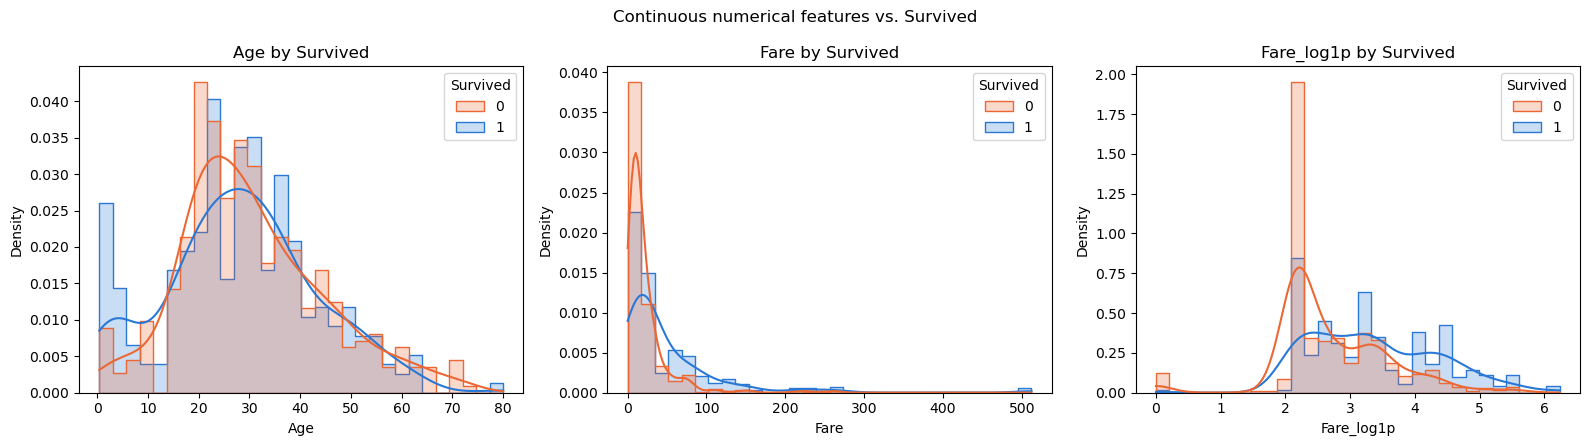

In [9]:
# Fare is heavily right-skewed -> also plot log1p(Fare) (plot only; train is not modified)
plot_df   = train.assign(Fare_log1p=np.log1p(train["Fare"]))
plot_cols = cont_cols + ["Fare_log1p"]

fig, axes = plt.subplots(1, len(plot_cols), figsize=(16, 4.5))

for ax, col in zip(axes, plot_cols):
    sns.histplot(
        data=plot_df, x=col, hue=TARGET, palette=PALETTE,
        bins=30, stat="density", common_norm=False,
        kde=True, element="step", ax=ax,
    )
    ax.set_title(f"{col} by Survived")

plt.suptitle("Continuous numerical features vs. Survived")
plt.tight_layout()
plt.show()

**Survival Rate by Binned Continuous Features**

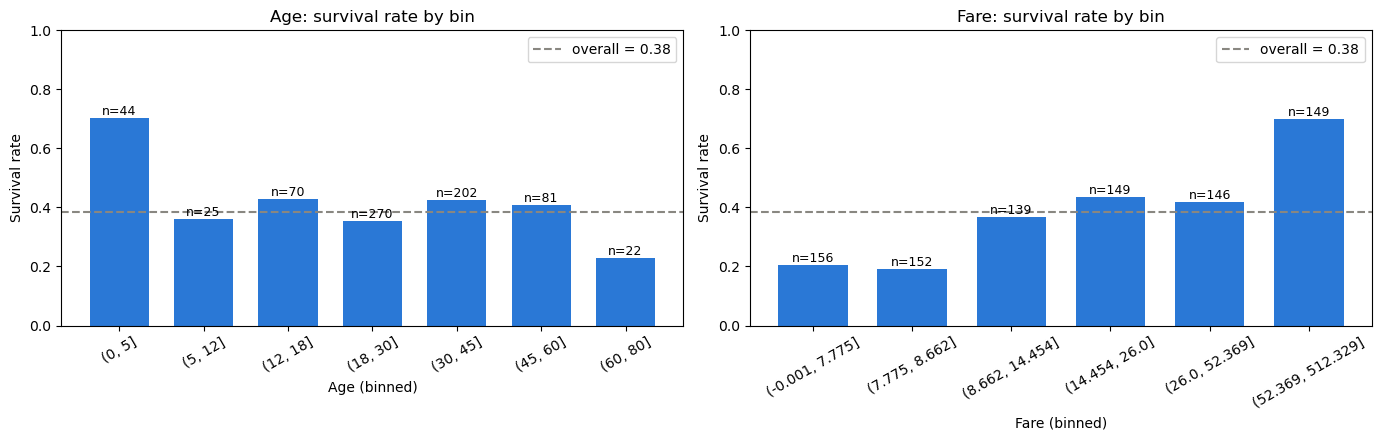

In [10]:
binned = {
    "Age":  pd.cut(train["Age"], bins=[0, 5, 12, 18, 30, 45, 60, 80]),
    "Fare": pd.qcut(train["Fare"], q=6, duplicates="drop"),
}

fig, axes = plt.subplots(1, len(binned), figsize=(14, 4.5))

for ax, (col, key) in zip(axes, binned.items()):
    plot_survival_rate(ax, key, f"{col}: survival rate by bin")
    ax.set_xlabel(f"{col} (binned)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

#### 2.4. Numerical column VS Survived (exclude many unique column)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


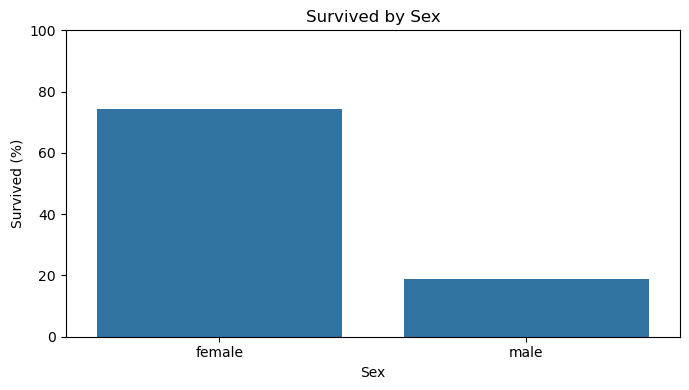

Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: Survived, dtype: float64


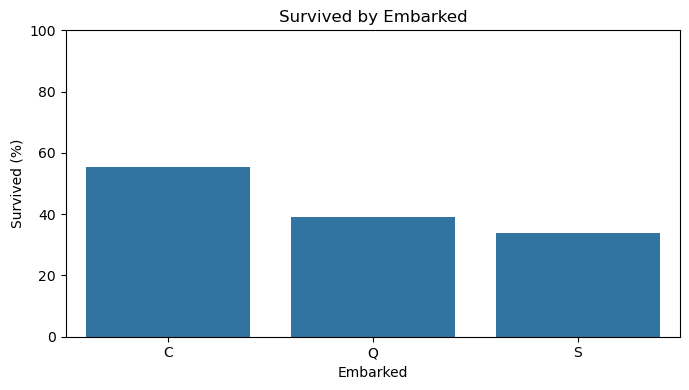

In [11]:
less_unique = ["Sex", "Embarked"]

for col in less_unique:
    satisfaction_rate = (
        train.groupby(col)[TARGET].mean()*100
    )
    #print('\n', col)
    print(satisfaction_rate)
    plt.figure(figsize=(7, 4))

    sns.barplot(
        x = satisfaction_rate.index,
        y = satisfaction_rate.values
    )

    plt.title(f'Survived by {col}')
    plt.ylabel('Survived (%)')
    plt.xlabel(col)
    plt.ylim(0, 100)

    plt.tight_layout()
    plt.show()

#### 2.5. Missing value imputation

##### 2.5.1. imputing Age

Check survived rate whether is there any difference missing and non-missing in 'Age' missing value

In [12]:
# Create BEFORE imputing Age (after fillna, isna() is all False)
for df in (train, test):
    df["Age_missing"] = df["Age"].isna().astype(int)

train.groupby("Age_missing")[TARGET].agg(["mean", "size"])   # check

,mean,size
Age_missing,,
0,0.406162,714
1,0.293785,177


Ckeck correlation between Age and Pclass

In [13]:
train.groupby(["Pclass", "Age_missing"])[TARGET].agg(["mean", "size"])

mean  size
Pclass Age_missing                
1      0            0.655914   186
       1            0.466667    30
2      0            0.479769   173
       1            0.363636    11
3      0            0.239437   355
       1            0.250000   136

Survival rate by family size and Age

In [ ]:
train["AgeBand"] = pd.cut(train["Age"], np.arange(0, 100, 10), right=False) 

train['FamilySize'] = train['SibSp'] + train['Parch'] + 1
train['FamilyGroup'] = pd.cut(train['FamilySize'], [0, 1, 4, 11], labels=['alone', 'small(2-4)', 'large(5+)'])
train.pivot_table(index='AgeBand', columns='FamilyGroup', values='Survived', aggfunc=['mean', 'count'], observed=False).round(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Age_missing,FamilySize
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208,0.198653,1.904602
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429,0.399210,1.613459
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400,0.000000,1.000000
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200,0.000000,1.000000
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000,0.000000,2.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,1.000000,11.000000


In [ ]:
train['is_Child'] = (train['Age'] <= 12).astype(int)
train['is_Alone'] = ((train['SibSp'] == 0) & (train['Parch'] == 0)).astype(int)



,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Age_missing,FamilySize,is_Child,is_Alone
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208,0.198653,1.904602,0.077441,0.602694
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429,0.399210,1.613459,0.267440,0.489615
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400,0.000000,1.000000,0.000000,0.000000
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200,0.000000,1.000000,0.000000,1.000000
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000,0.000000,2.000000,0.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,1.000000,11.000000,1.000000,1.000000


In [23]:
train  = train_0.copy()


for df in (train, test):
    df["Cabin_missing"] = df["Cabin"].isna().astype(int)

train.groupby("Cabin_missing")[TARGET].agg(["mean", "size"]).round(3) 

,mean,size
Cabin_missing,,
0,0.667,204
1,0.300,687


In [24]:
# Cabin missing rate by Pclass
train["Cabin"].isna().groupby(train["Pclass"]).mean().round(2)

Pclass
1    0.19
2    0.91
3    0.98
Name: Cabin, dtype: float64

> This result shows 1st. class passenger tend to memory their Cabin, the others seems to be unknown  
> This fact may affect survive or not since the person who does not know their Cabin are uncertain the room location in Titanic

In [25]:
for df in (train, test):
    df["Has_Cabin"] = df["Cabin"].notna().astype(int)   # 1 = cabin recorded
    df["Deck"]      = df["Cabin"].str[0].fillna("U")    # first letter (A-G, T), U = Unknown

# Stratify by Pclass (same idea as Age_missing)
train.groupby(["Pclass", "Has_Cabin"])[TARGET].agg(["mean", "size"])

mean  size
Pclass Has_Cabin                
1      0          0.475000    40
       1          0.664773   176
2      0          0.440476   168
       1          0.812500    16
3      0          0.235908   479
       1          0.500000    12

In [26]:
train.groupby("Deck")[TARGET].agg(["mean", "size"])

,mean,size
Deck,,
A,0.466667,15
B,0.744681,47
C,0.593220,59
D,0.757576,33
E,0.750000,32
F,0.615385,13
G,0.500000,4
T,0.000000,1
U,0.299854,687
